# Entity binding en un LLM abierto: los siete pasos

**10 de noviembre de 2026 · Felipe Urrutia · MIA 2026-2**

En la clase seguimos siete pasos para explicar cómo un Transformer de juguete resuelve la inducción:
observar → proponer → demostrar a mano → caracterizar → intervenir → descomponer → confirmar.

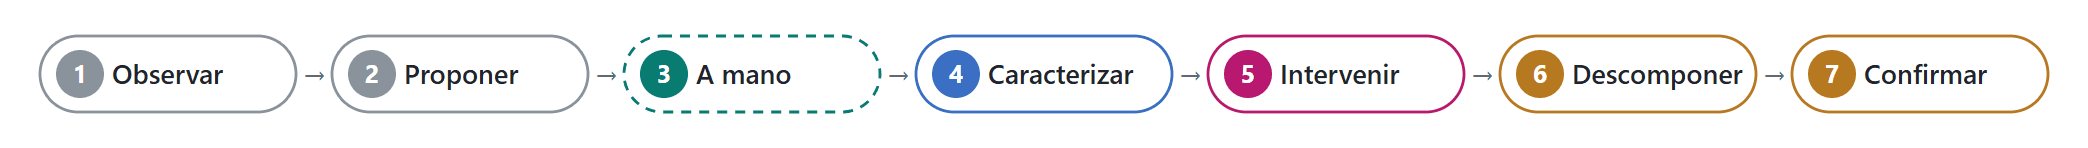

Aquí repetimos el ejercicio en un modelo de lenguaje real de pesos abiertos, **Qwen2.5-1.5B-Instruct**, con una tarea de
*entity binding*:

```
Each object has a color. key is orange. cup is pink. bag is red. … chair is black.
The cup is  →  " pink"
```

El modelo debe **ligar** cada objeto con su color y, al leer la pregunta, recuperar el color del objeto consultado.
La pregunta es la misma que en la clase: **¿cómo lo hace?**

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. En la T4 el modelo corre en float32
(float16 desborda en Qwen2.5) y todo el notebook tarda unos 12 minutos; en CPU, más de una hora (usa `RAPIDO = 0.2` para
una pasada corta).

**Cómo usarlo:** cada sección empieza con una pregunta. **Escribe tu predicción antes de correr la celda**; después abre
«Lo que encontramos» para comparar con nuestra corrida. Las muestras son chicas (decenas a cientos de prompts), así que tus
números pueden variar unos puntos.

## 0 · Preparación

In [ ]:
# En Colab, transformers, torch, scikit-learn y matplotlib ya vienen instalados.
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = os.environ.get('MODEL_ID', 'Qwen/Qwen2.5-1.5B-Instruct')   # prueba también Qwen/Qwen2.5-0.5B-Instruct o -3B-Instruct
RAPIDO = float(os.environ.get('RAPIDO', 1))   # < 1 usa menos ejemplos (p. ej. 0.2 en CPU)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)

# Precisión numérica: float16 desborda en Qwen2.5 con atención 'eager' (activaciones inf/NaN → modelo al azar).
# Usamos bfloat16 en GPUs que lo soportan (A100, L4, …) y float32 en la T4 y en CPU (1.5B en float32 ≈ 6 GB).
supports_bf16 = DEV == 'cuda' and torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if supports_bf16 else torch.float32

tok = AutoTokenizer.from_pretrained(MODEL_ID)
load_args = dict(attn_implementation='eager')   # 'eager' devuelve los patrones de atención
try:
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, **load_args)
except TypeError:                                 # transformers < 4.56 usa torch_dtype
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, **load_args)
model = model.to(DEV).eval()

L = model.config.num_hidden_layers                # número de capas
H = model.config.num_attention_heads              # cabezas por capa
HD = getattr(model.config, 'head_dim', None) or model.config.hidden_size // H   # dimensión de cada cabeza
print(f'{MODEL_ID} en {DEV} ({DTYPE}): {L} capas × {H} cabezas (d_cabeza = {HD})')

# Colores de los gráficos (los mismos de las diapositivas)
GRAY, BLUE, PINK, GREEN, AMBER = '#64748b', '#2563eb', '#be185d', '#0f766e', '#b45309'

def scaled(n):
    """Número de ejemplos a usar: n reducido por RAPIDO (mínimo 8)."""
    return max(8, int(n * RAPIDO))

## 1 · La tarea

Cada contexto tiene `NP = 8` pares objeto–color, elegidos al azar, y una pregunta por uno de ellos. Usamos solo objetos y
colores que son **un token** (con espacio inicial) en el tokenizador del modelo: así todos los prompts tienen el mismo largo
y las posiciones se alinean, lo que necesitaremos para el *patching*.

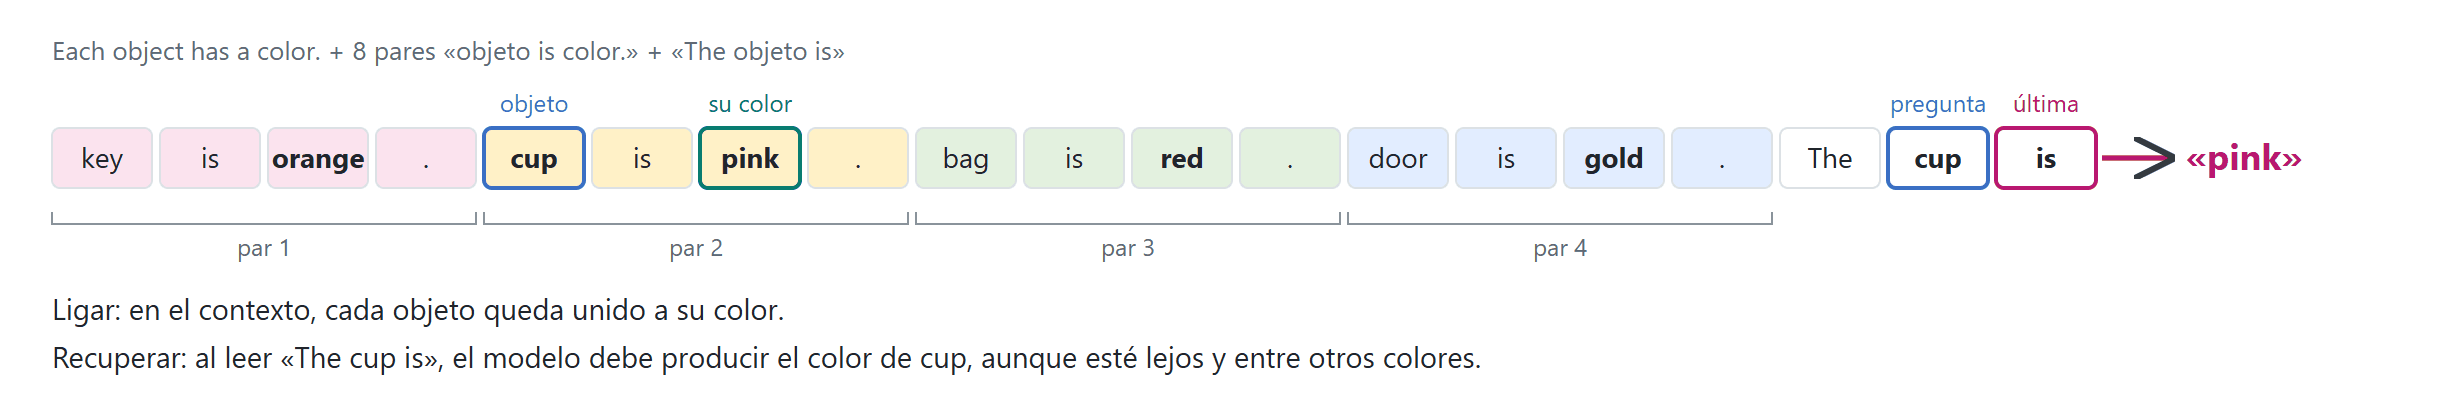

In [ ]:
OBJS = ('key cup bag door car book table chair hat box pen lamp ball coin ring bowl shoe bed clock phone bike bottle '
        'fork knife spoon plate desk sofa map card bell rope kite drum').split()
COLS = 'orange pink red brown yellow blue black green white gray purple gold silver'.split()
NP = 8   # pares por contexto


def is_single_token(word):
    return len(tok.encode(' ' + word, add_special_tokens=False)) == 1


OBJS = [o for o in OBJS if is_single_token(o)]
COLS = [c for c in COLS if is_single_token(c)]
CID = {c: tok.encode(' ' + c, add_special_tokens=False)[0] for c in COLS}   # color → id de su token
print(len(OBJS), 'objetos y', len(COLS), 'colores de un token')


def make_prompt(pairs, q):
    """pairs = [(objeto, color), ...]; q = índice del par por el que se pregunta."""
    context = ' '.join(f'{obj} is {col}.' for obj, col in pairs)
    return f'Each object has a color. {context}\nThe {pairs[q][0]} is'


def sample_pairs(rng, n_pairs=NP):
    """Elige n_pairs objetos y colores distintos al azar, y el par por el que se pregunta."""
    objects = rng.sample(OBJS, n_pairs)
    colors = rng.sample(COLS, n_pairs)
    q = rng.randrange(n_pairs)
    return list(zip(objects, colors)), q


def encode(pairs, q):
    """Tokeniza el prompt. Devuelve los ids y, para cada par k, (posición del objeto, posición del color)."""
    text = make_prompt(pairs, q)
    enc = tok(text, return_tensors='pt', return_offsets_mapping=True)
    offsets = enc['offset_mapping'][0].tolist()          # (inicio, fin) en caracteres de cada token

    def token_at(char):
        return next(i for i, (start, end) in enumerate(offsets) if start <= char < end)

    positions = []
    cursor = text.index('. ') + 1                         # después de «Each object has a color.»
    for obj, col in pairs:
        obj_char = text.index(f' {obj} is', cursor)
        col_char = text.index(f' {col}.', obj_char)
        positions.append((token_at(obj_char + 1), token_at(col_char + 1)))
        cursor = col_char + len(col) + 2
    return enc['input_ids'].to(DEV), positions


@torch.no_grad()
def run_model(ids, **kwargs):
    return model(ids, **kwargs)


def choose_among_context(logits, pairs):
    """La elección del modelo entre los colores del contexto: índice del par cuyo color tiene el mayor logit."""
    color_logits = torch.stack([logits[CID[col]] for _, col in pairs])
    return int(color_logits.argmax())


# Un ejemplo
rng = random.Random(0)
pairs, q = sample_pairs(rng)
ids, pos = encode(pairs, q)
print(make_prompt(pairs, q))
print('\nrespuesta:', pairs[q][1], '| tokens:', ids.shape[1])
print([tok.decode(int(t)) for t in ids[0]])

## 2 · Comportamiento: ¿resuelve la tarea?

Como en la clase, antes de interpretar necesitamos un modelo que **acierte**.

> **Predice:** ¿qué exactitud esperas entre los 8 colores del contexto (azar = 12.5%)? ¿Depende de la posición del par consultado?

In [ ]:
def behavior(n_prompts, seed=0, n_pairs=NP):
    """Exactitud por posición del par consultado, exactitud global y top-1 sobre todo el vocabulario."""
    rng = random.Random(seed)
    correct = np.zeros(n_pairs)
    count = np.zeros(n_pairs)
    top1 = 0
    for _ in range(n_prompts):
        pairs, q = sample_pairs(rng, n_pairs)
        ids, _ = encode(pairs, q)
        logits = run_model(ids).logits[0, -1]
        correct[q] += choose_among_context(logits, pairs) == q
        count[q] += 1
        top1 += int(logits.argmax()) == CID[pairs[q][1]]
    return correct / np.maximum(count, 1), correct.sum() / count.sum(), top1 / n_prompts


t0 = time.time()
acc_by_pos, acc, top1 = behavior(scaled(240))
print(f'exactitud entre los colores del contexto: {acc:.1%}')
print(f'top-1 sobre todo el vocabulario: {top1:.1%}   ({time.time() - t0:.0f}s)')
assert acc > 3 / NP, ('El modelo está al azar: revisa la precisión numérica (float16 produce NaN en Qwen2.5) '
                      'o el formato del prompt antes de seguir.')

plt.figure(figsize=(7, 3))
plt.bar(range(1, NP + 1), acc_by_pos, color=GREEN)
plt.axhline(1 / NP, ls='--', c='gray', label='azar')
plt.xlabel('posición del par consultado')
plt.ylabel('exactitud')
plt.ylim(0, 1.05)
plt.legend()
plt.show()

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>95.0%</b> entre los 8 colores del contexto y <b>79.6%</b> top-1 sobre todo el vocabulario (a veces prefiere otra palabra, no otro color).</li><li>Por posición: <b>100%</b> en los pares 1–2, ≈97% en los pares 3–5 y ≈88% en los pares 6–8. Los últimos pares, más cercanos a la pregunta, son un poco más difíciles.</li></ul></details>

**Tu turno (opcional).** Cambia el número de pares con `behavior(scaled(120), n_pairs=4)` y `n_pairs=12`. ¿Cae la exactitud
con más pares? ¿En qué posiciones? (Hay a lo más 13 colores, así que `n_pairs ≤ 13`.)

In [ ]:
# for n_pairs in (4, 12):
#     acc_by_pos_n, acc_n, _ = behavior(scaled(120), n_pairs=n_pairs)
#     print(n_pairs, f'{acc_n:.1%}', np.round(acc_by_pos_n, 2))

## 3 · Paso 1 · Observar: logit lens y patrones de atención

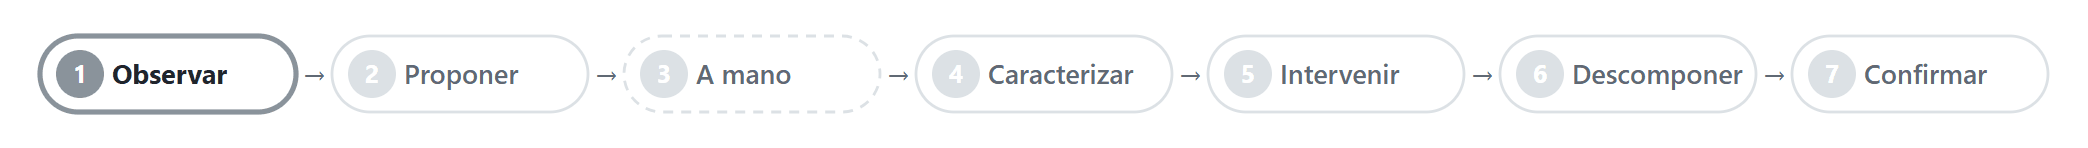

Dos herramientas para mirar sin intervenir:

- **Logit lens:** proyectamos el residual de la última posición de cada capa con la capa final (norma + *unembedding*). ¿Desde
  qué capa el color correcto ya es la predicción?
- **Patrones de atención:** para cada capa y cabeza, ¿cuánto atiende la última posición (` is`) al **objeto en la pregunta**
  (dos tokens antes), al **mismo objeto dentro del contexto** y al **token del color correcto**?

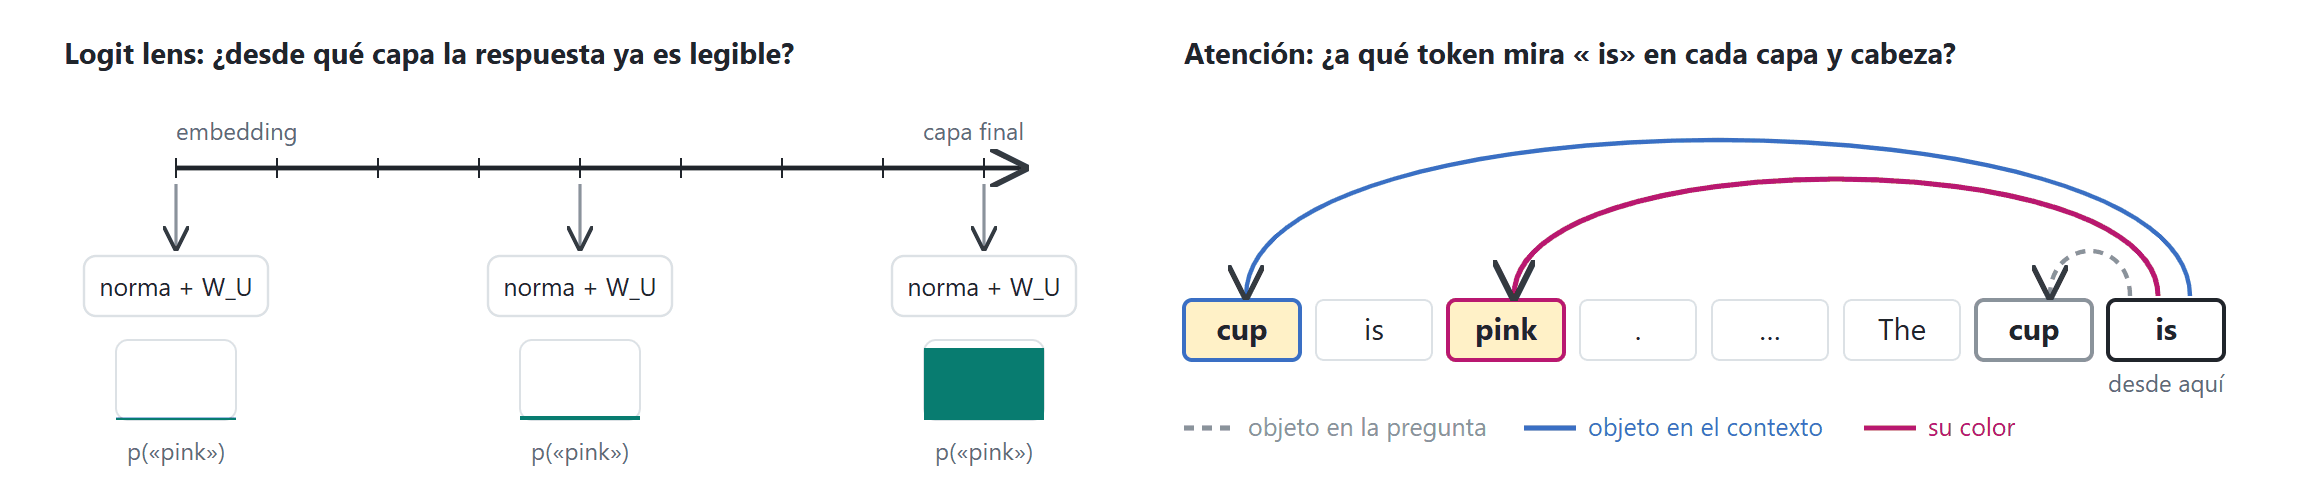

> **Predice:** ¿en qué tramo de capas aparece la respuesta? ¿Esperas muchas cabezas que miran al color, o pocas?

In [ ]:
rng = random.Random(1)
N_OBS = scaled(120)
lens_prob = np.zeros(L + 1)        # p(color correcto) según el logit lens, por capa
lens_top1 = np.zeros(L + 1)        # ¿es el color correcto el token más probable?
to_answer = np.zeros((L, H))       # atención desde la última posición al color correcto, por capa y cabeza
to_object = np.zeros((L, H))       # ... al mismo objeto dentro del contexto
to_question = np.zeros((L, H))     # ... al objeto en la pregunta («The desk is»), dos tokens antes
example = None

for n in range(N_OBS):
    pairs, q = sample_pairs(rng)
    ids, pos = encode(pairs, q)
    out = run_model(ids, output_hidden_states=True, output_attentions=True)
    answer_id = CID[pairs[q][1]]
    obj_pos, col_pos = pos[q]
    question_pos = ids.shape[1] - 2

    # logit lens: norma final + unembedding sobre el residual de la última posición
    for l, hidden in enumerate(out.hidden_states):
        h = hidden[0, -1]
        if l < L:                                   # el último estado ya viene normalizado
            h = model.model.norm(h)
        probs = torch.softmax(model.lm_head(h).float(), -1)
        lens_prob[l] += probs[answer_id].item() / N_OBS
        lens_top1[l] += float(probs.argmax() == answer_id) / N_OBS

    # atención: fila de la última posición (query = « is») hacia los tres tokens
    for l, A in enumerate(out.attentions):          # A: (1, cabezas, query, key)
        last_row = A[0, :, -1].float().cpu().numpy()
        to_answer[l] += last_row[:, col_pos] / N_OBS
        to_object[l] += last_row[:, obj_pos] / N_OBS
        to_question[l] += last_row[:, question_pos] / N_OBS

    if n == 0:
        example = (pairs, q, ids, pos)

plt.figure(figsize=(7, 3))
plt.plot(lens_prob, label='p(color correcto)', c=GREEN)
plt.plot(lens_top1, '--', label='top-1 = correcto', c=PINK)
plt.xlabel('capa (0 = embedding)')
plt.ylabel('última posición')
plt.ylim(0, 1.02)
plt.title('Logit lens')
plt.legend()
plt.show()

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li>El color correcto <b>no aparece hasta la capa ≈25</b>: antes su probabilidad es ≈0. En la capa final, top-1 ≈80% y p(color) ≈0.30.</li><li>La respuesta se escribe tarde. El logit lens solo muestra cuándo es <i>legible</i> por el unembedding, no cuándo se calcula.</li></ul></details>

In [ ]:
# Las 8 cabezas con más atención al color correcto (las usaremos en la ablación)
scores = sorted(((to_answer[l, h], l, h) for l in range(L) for h in range(H)), reverse=True)[:8]
top_heads = [(l, h) for _, l, h in scores]

panels = [(to_question, 'al OBJETO en la pregunta («The desk is»)'),
          (to_object, 'al mismo OBJETO en el contexto («desk is green»)'),
          (to_answer, 'al COLOR correcto')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (M, title) in zip(axes, panels):
    im = ax.imshow(M, aspect='auto', cmap='Greens')
    ax.set_title(f'atención desde la última posición\n{title}')
    ax.set_xlabel('cabeza')
    ax.set_ylabel('capa')
    plt.colorbar(im, ax=ax)
for l, h in top_heads[:4]:                         # marco rosa: las 4 mejores cabezas de recuperación
    axes[2].add_patch(plt.Rectangle((h - .5, l - .5), 1, 1, fill=False, ec=PINK, lw=2))
plt.tight_layout()
plt.show()

print('cabezas con más atención al color correcto (capa, cabeza, peso medio):')
for score, l, h in scores:
    print(f'  L{l}.H{h}: {score:.2f}')

In [ ]:
# Un ejemplo: para cada uno de los tres tokens, la cabeza que más lo mira y su fila de atención desde « is»
pairs, q, ids, pos = example
attentions = run_model(ids, output_attentions=True).attentions
tokens = [tok.decode(int(t)) for t in ids[0]]
start = pos[0][0]                                   # mostramos desde el primer objeto
n_tok = len(tokens)
targets = [('objeto en la pregunta', to_question, n_tok - 2, GRAY),
           ('mismo objeto en el contexto', to_object, pos[q][0], BLUE),
           ('color correcto', to_answer, pos[q][1], PINK)]

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (name, M, target, color) in zip(axes, targets):
    l, h = np.unravel_index(M.argmax(), M.shape)   # la cabeza con más atención media a ese token
    row = attentions[l][0, h, -1].float().cpu().numpy()
    ax.bar(range(n_tok - start), row[start:], color='#cbd5e1')
    ax.bar([target - start], [row[target]], color=color, label=f'{name}: «{tokens[target].strip()}»')
    ax.set_title(f'L{l}.H{h} · la cabeza con más atención al {name} (media {M[l, h]:.2f})', fontsize=11, loc='left')
    ax.set_ylabel('atención')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
axes[-1].set_xticks(range(n_tok - start))
axes[-1].set_xticklabels(tokens[start:], rotation=90)
plt.tight_layout()
plt.show()

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>Objeto en la pregunta:</b> muchas cabezas, en todas las profundidades (L1.H4 = 0.90, y otras en las capas 13, 18 y 24). El modelo relee su propia entidad una y otra vez.</li><li><b>Mismo objeto en el contexto:</b> débil y difuso (máximo ≈0.15, en las capas 20–21). En el ejemplo, la «mejor» cabeza (L21.H8) mira tanto al objeto como a su color y a otros colores: no es una cabeza limpia de búsqueda.</li><li><b>Color correcto:</b> pocas cabezas y muy nítidas: L19.H1 (0.59), L14.H3 (0.49), L22.H7 (0.49), L20.H9 (0.42), L14.H0 (0.39). Son <i>cabezas de recuperación</i>.</li></ul></details>

## 4 · Paso 2 · Proponer una hipótesis

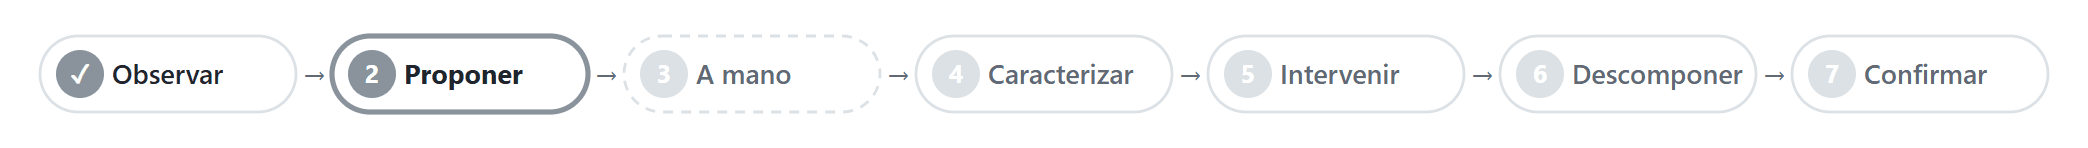

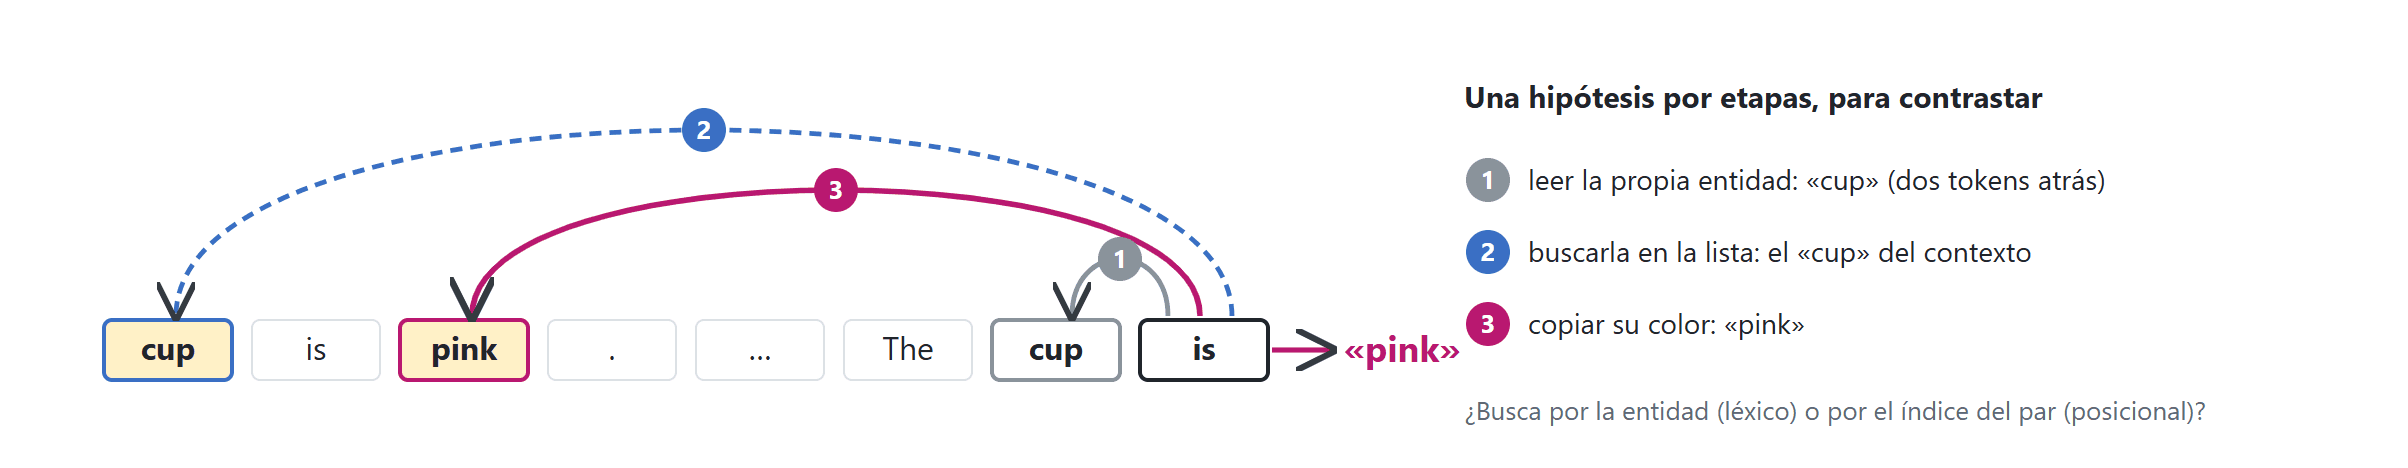

Con lo observado, escribe una hipótesis **por etapas**, como hicimos con las dos capas del modelo de juguete. Una plantilla:

1. Hasta la capa ___, la última posición **localiza** el objeto consultado en el contexto (atención al objeto).
2. Algunas cabezas (¿cuáles?) **recuperan** el color ligado a ese objeto y lo copian a la última posición.
3. Desde la capa ___, el color está en el residual y el *unembedding* lo lee (logit lens).

Una pregunta abierta en la literatura (Feng & Steinhardt, 2023; Dai et al., 2024): ¿el modelo busca el par **por la
entidad** (léxico: «cup») o **por su índice** en la lista (posicional: «el 2.º par»)? Anota qué esperas; el paso 5 lo pone
a prueba.

> **Tu hipótesis:** …

## 5 · Paso 3 · Demostrar a mano

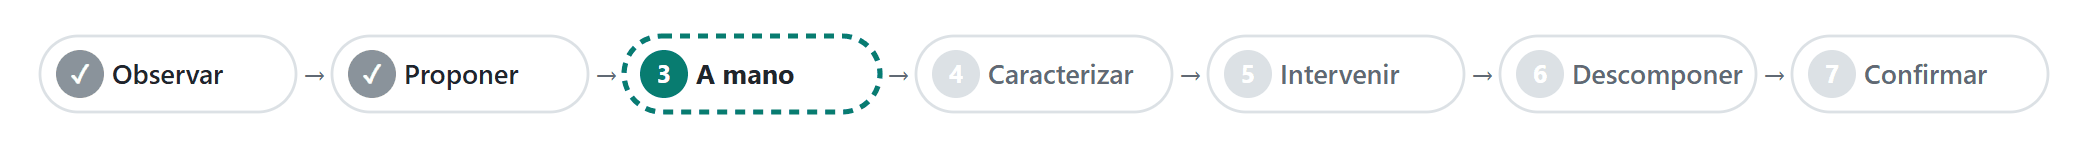

En el modelo de juguete escribimos los pesos de las dos cabezas y mostramos que el mecanismo **basta** para resolver la
tarea. En un LLM de 1.5 mil millones de parámetros eso no es viable: aquí este paso queda como pregunta conceptual.

> **Discute:** ¿cuál sería la versión mínima del mecanismo (cuántas capas, qué debe escribir cada una)? Pista: es el mismo
> patrón «buscar y copiar» de la inducción, pero la clave de búsqueda es la entidad, no el token previo.

## 6 · Paso 4 · Caracterizar: ¿qué capas buscan y cuáles copian?

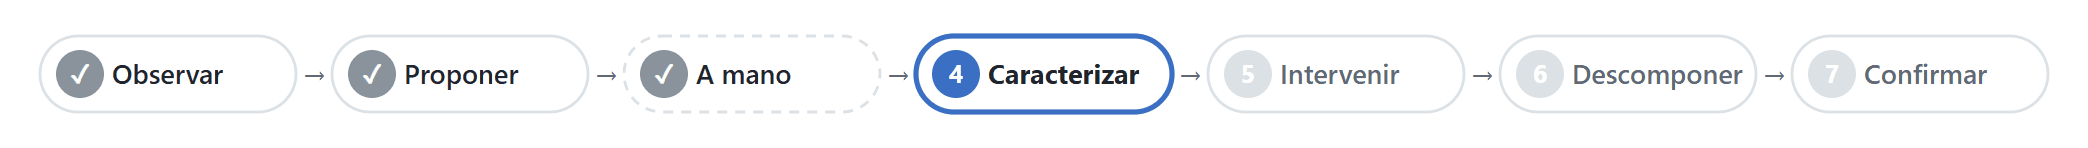

Si la hipótesis es correcta, la última posición primero lee **su propia entidad** (el objeto en la pregunta, dos tokens
antes), luego la **busca en la lista** (el mismo objeto en el contexto) y al final **copia el color**. Resumimos por capa la
atención desde la última posición a esos tres tokens (máximo sobre las cabezas).

> **Predice:** ¿en qué orden suben las tres curvas?

In [ ]:
plt.figure(figsize=(12, 3.2))
plt.plot(to_question.max(1), label='objeto en la pregunta («The desk is»)', c=GRAY, ls='--')
plt.plot(to_object.max(1), label='mismo objeto en el contexto («desk is green»)', c=BLUE)
plt.plot(to_answer.max(1), label='color correcto en el contexto', c=PINK)
plt.xlabel('capa')
plt.ylabel('máx. peso de atención')
plt.title('Atención desde la última posición')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()
plt.show()

for name, M in (('objeto en la pregunta', to_question), ('objeto en el contexto', to_object), ('color correcto', to_answer)):
    print(f'{name:>22}: capa con más atención {int(M.max(1).argmax())}')

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li>Objeto en la pregunta: máximo en la <b>capa 1</b>, y alto (≈0.5–0.9) hasta la capa ≈24.</li><li>Objeto en el contexto: máximo en la <b>capa 21</b>. Color correcto: máximo en la <b>capa 19</b> (y picos en 14 y 22).</li><li><b>La hipótesis «primero buscar el objeto, después copiar el color» no se sostiene:</b> la búsqueda del objeto en la lista no ocurre antes que la copia del color, sino en la misma franja. Eso pide otra explicación (la siguiente celda).</li></ul></details>

### ¿Sabe cada color a qué objeto pertenece?

Las cabezas de recuperación van **directo al color**, sin pasar antes por el objeto en el contexto. Para que eso funcione,
el token del color («gold» en «ring is gold») debe llevar en su residual **a qué objeto pertenece**, y la pregunta («ring»)
compararse con eso. Es el mismo truco de la inducción: en el modelo de juguete, la capa 1 copiaba en cada posición su
**token previo** y la capa 2 buscaba por ese «previo».

| | inducción (modelo de juguete) | binding (Qwen) |
|---|---|---|
| paso previo | capa 1: cada posición copia su **token previo** | ¿alguna cabeza copia en «gold» **su objeto** «ring» (dos tokens atrás)? |
| búsqueda | la query compara con «previo = C» | la pregunta «ring» compara con «mi objeto = ring» |
| copia | el value es el propio token → «D» | el value es el propio color → «gold» |

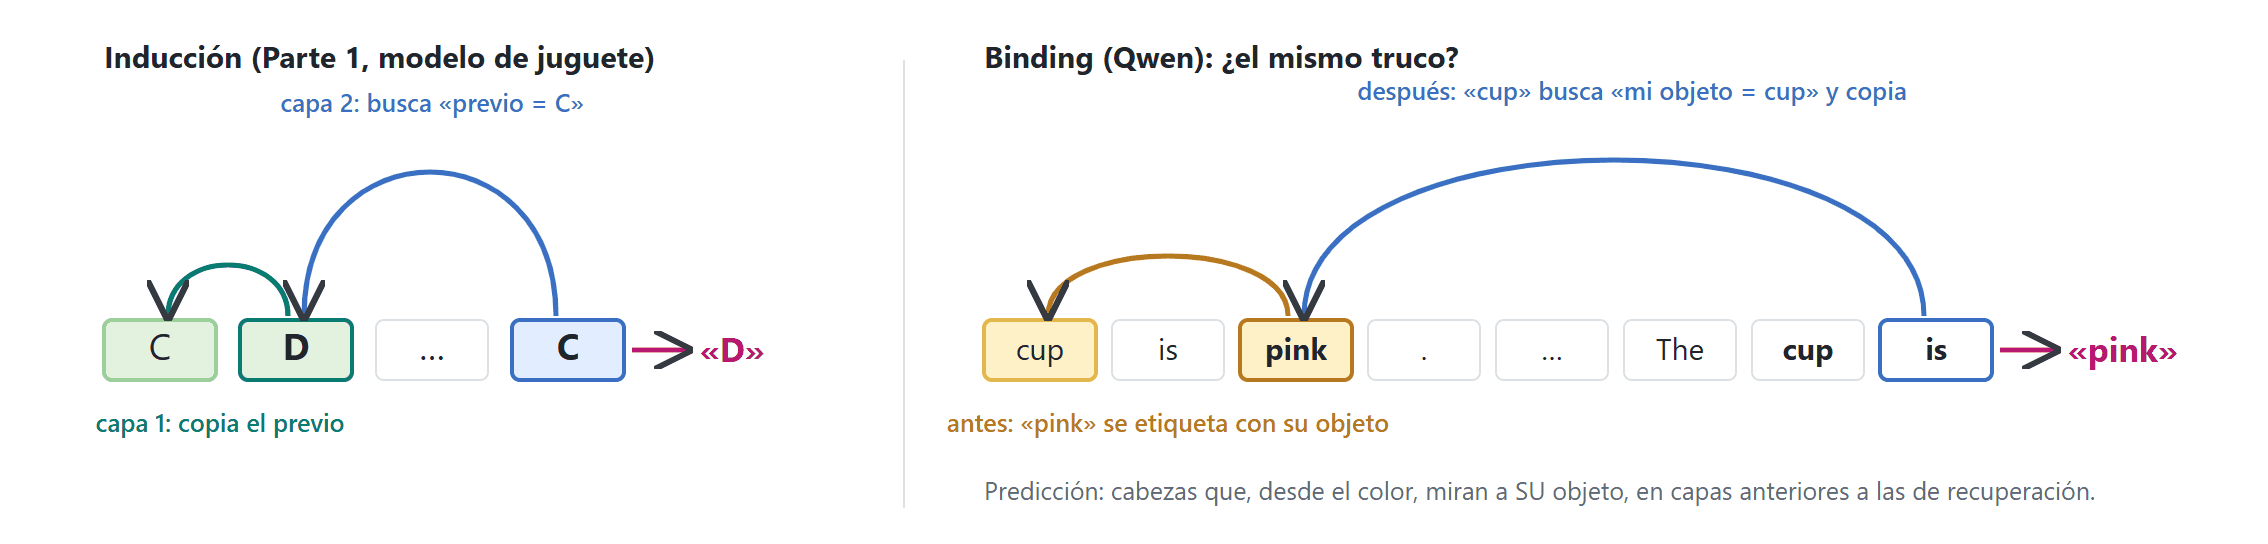

Medimos, en cada capa y cabeza, la atención **desde cada token de color hacia su propio objeto**, y la comparamos con la
atención hacia los **otros objetos** anteriores del contexto (control).

> **Predice:** si estas cabezas existen, ¿en qué capas deberían estar respecto de las de recuperación (14–22)?

In [ ]:
rng = random.Random(11)
N_TAG = scaled(60)
color_to_own = np.zeros((L, H))     # atención desde cada color a SU objeto
color_to_other = np.zeros((L, H))   # control: atención media desde cada color a los objetos de pares anteriores
n_own = 0
n_other = 0
tag_example = None

for n in range(N_TAG):
    pairs, q = sample_pairs(rng)
    ids, pos = encode(pairs, q)
    attentions = [A[0].float().cpu().numpy() for A in run_model(ids, output_attentions=True).attentions]  # L × (H, T, T)
    for k, (obj_pos, col_pos) in enumerate(pos):
        earlier_objects = [pos[j][0] for j in range(k)]       # por la máscara causal, solo los anteriores son visibles
        for l in range(L):
            color_to_own[l] += attentions[l][:, col_pos, obj_pos]
            if earlier_objects:
                color_to_other[l] += attentions[l][:, col_pos, earlier_objects].mean(-1)
        n_own += 1
        n_other += bool(earlier_objects)
    if n == 0:
        tag_example = (pairs, q, ids, pos, attentions)
color_to_own /= n_own
color_to_other /= max(n_other, 1)

tag_scores = sorted(((color_to_own[l, h], l, h) for l in range(L) for h in range(H)), reverse=True)[:6]
tag_heads = [(l, h) for _, l, h in tag_scores]          # las cabezas que «etiquetan» cada color con su objeto

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[1, 1.4]))
im = axes[0].imshow(color_to_own, aspect='auto', cmap='Greens')
plt.colorbar(im, ax=axes[0])
for l, h in tag_heads[:4]:
    axes[0].add_patch(plt.Rectangle((h - .5, l - .5), 1, 1, fill=False, ec=AMBER, lw=2))
axes[0].set_title('atención desde cada COLOR a SU objeto')
axes[0].set_xlabel('cabeza')
axes[0].set_ylabel('capa')
axes[1].plot(color_to_own.max(1), c=AMBER, label='color → su objeto (máx. sobre cabezas)')
axes[1].plot(color_to_other.max(1), c='#94a3b8', ls='--', label='color → otro objeto anterior (control)')
axes[1].plot(to_answer.max(1), c=PINK, alpha=.5, label='pregunta → color correcto (recuperación)')
axes[1].set_xlabel('capa')
axes[1].set_ylabel('máx. peso de atención')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()
plt.show()

print('cabezas color → su objeto (capa, cabeza, peso medio):')
for score, l, h in tag_scores:
    print(f'  L{l}.H{h}: {score:.2f}   (control, otro objeto: {color_to_other[l, h]:.2f})')

# La mejor de estas cabezas en un ejemplo, desde el color del par consultado
pairs, q, ids, pos, attentions = tag_example
l, h = tag_heads[0]
obj_pos, col_pos = pos[q]
tokens = [tok.decode(int(t)) for t in ids[0]]
start = pos[0][0]
row = attentions[l][h, col_pos]
plt.figure(figsize=(14, 2.6))
plt.bar(range(col_pos + 1 - start), row[start:col_pos + 1], color='#cbd5e1')
plt.bar([obj_pos - start], [row[obj_pos]], color=AMBER, label=f'su objeto «{tokens[obj_pos].strip()}»')
plt.xticks(range(col_pos + 1 - start), tokens[start:col_pos + 1], rotation=90)
plt.title(f'L{l}.H{h}: atención desde el color «{tokens[col_pos].strip()}» (solo puede mirar hacia atrás)', loc='left', fontsize=11)
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()
plt.show()

> **Lee el resultado:** ¿hay cabezas que, desde el color, miran a **su** objeto mucho más que a los demás? ¿Están en capas
> **anteriores** a las de recuperación, como la capa 1 antes que la capa 2 en el modelo de juguete? Si es así, tenemos la
> mitad que faltaba del circuito. En el paso 5 (sección 7c) lo ponemos a prueba con una intervención.

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>L13.H7</b> (0.61), <b>L13.H2</b> (0.51), L3.H10 (0.48), L7.H10 (0.48), L18.H0 (0.47) y L6.H0 (0.46). La atención a <i>otros</i> objetos es ≤0.07: son específicas.</li><li>Casi todas están <b>antes</b> de las cabezas de recuperación (14–22): mismo orden que en la inducción (capa 1 «copia el previo», capa 2 «busca y copia»).</li><li>Esto sigue siendo evidencia de atención, es decir, correlacional. La sección 7c muestra que no basta.</li></ul></details>

## 7 · Paso 5 · Intervenir

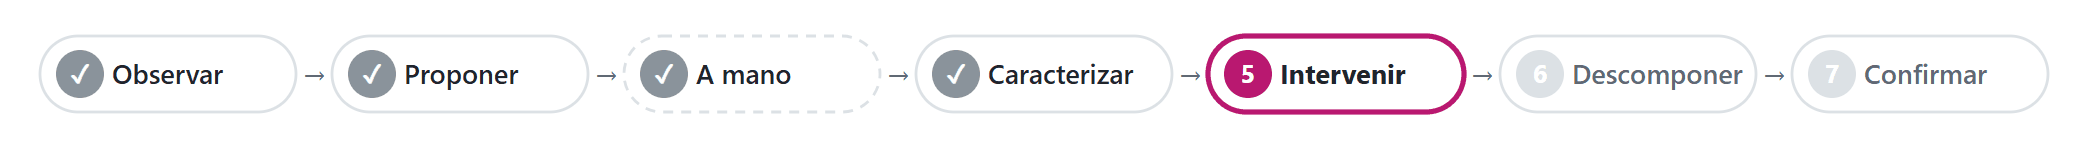

Hasta aquí todo es correlacional: que una cabeza mire al color no prueba que el modelo **la use**. Tres intervenciones.

### 7a · Ablación de las cabezas de recuperación

Ponemos en cero la salida de las cabezas con más atención al color correcto y comparamos con el mismo número de cabezas al
azar.

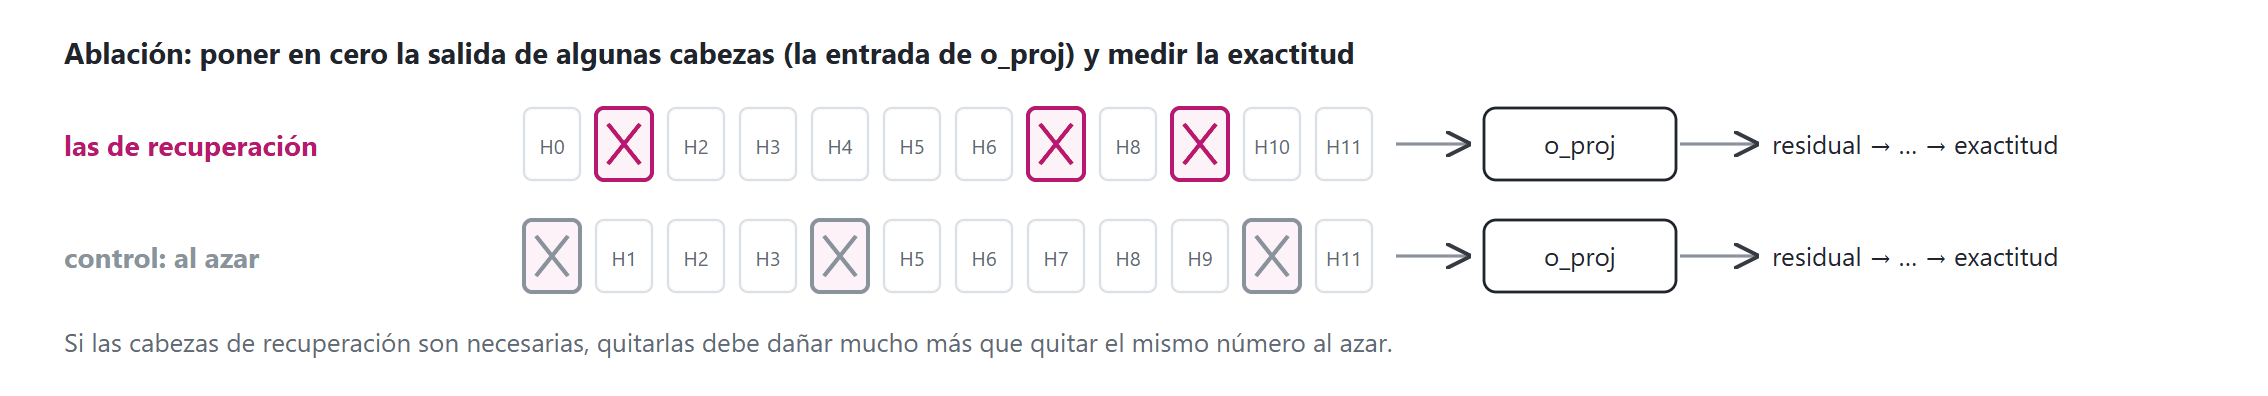

> **Predice:** ¿cuánto cae la exactitud al quitar 1, 4 y 8 cabezas? ¿Y con 8 al azar?

In [ ]:
def ablation_hooks(heads):
    """Pone en cero la salida de las cabezas (capa, cabeza) dadas, en todas las posiciones.
    La entrada de o_proj es la concatenación de las cabezas: la cabeza h ocupa las columnas [h·HD, (h+1)·HD)."""
    hooks = []
    for layer in sorted({l for l, _ in heads}):
        heads_here = [h for l, h in heads if l == layer]

        def zero_heads(module, args, heads_here=heads_here):
            x = args[0].clone()
            for h in heads_here:
                x[..., h * HD:(h + 1) * HD] = 0
            return (x,) + args[1:]

        o_proj = model.model.layers[layer].self_attn.o_proj
        hooks.append(o_proj.register_forward_pre_hook(zero_heads))
    return hooks


def accuracy_with_ablation(heads, n_prompts=None, seed=2):
    """Exactitud entre los colores del contexto con esas cabezas apagadas (mismos prompts para todas las condiciones)."""
    rng = random.Random(seed)
    n_prompts = n_prompts or scaled(120)
    hooks = ablation_hooks(heads)
    correct = 0
    try:
        for _ in range(n_prompts):
            pairs, q = sample_pairs(rng)
            ids, _ = encode(pairs, q)
            correct += choose_among_context(run_model(ids).logits[0, -1], pairs) == q
    finally:
        for hook in hooks:
            hook.remove()
    return correct / n_prompts


def random_heads(rng, k):
    all_heads = [(l, h) for l in range(L) for h in range(H)]
    return rng.sample(all_heads, k)


rng_ctrl = random.Random(3)
ablation = {
    'sin intervención': accuracy_with_ablation([]),
    'top-1': accuracy_with_ablation(top_heads[:1]),
    'top-4': accuracy_with_ablation(top_heads[:4]),
    'top-8': accuracy_with_ablation(top_heads),
    '8 al azar': np.mean([accuracy_with_ablation(random_heads(rng_ctrl, 8)) for _ in range(3)]),
}

plt.figure(figsize=(7, 3))
plt.barh(list(ablation)[::-1], list(ablation.values())[::-1], color=['#94a3b8', PINK, PINK, PINK, '#334155'])
plt.axvline(1 / NP, ls='--', c='gray')
plt.xlim(0, 1)
plt.xlabel('exactitud')
plt.show()
print({k: round(float(v), 3) for k, v in ablation.items()})

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li>Sin intervención 93.3% · top-1 90.8% · top-4 82.5% · <b>top-8 63.3%</b> · 8 al azar 94.2%.</li><li>Las cabezas de recuperación importan causalmente (8 al azar no dañan nada), pero quitarlas no lleva al azar: el mecanismo está repartido en más cabezas.</li></ul></details>

### 7b · Patching donante → receptor: ¿léxico o posicional?

Dos prompts con **los mismos objetos y colores**, en otro orden. Corremos el **receptor** copiando, en la capa ℓ, el
residual de la última posición del **donante**. El color que sale ahora dice qué información viaja en esa capa:

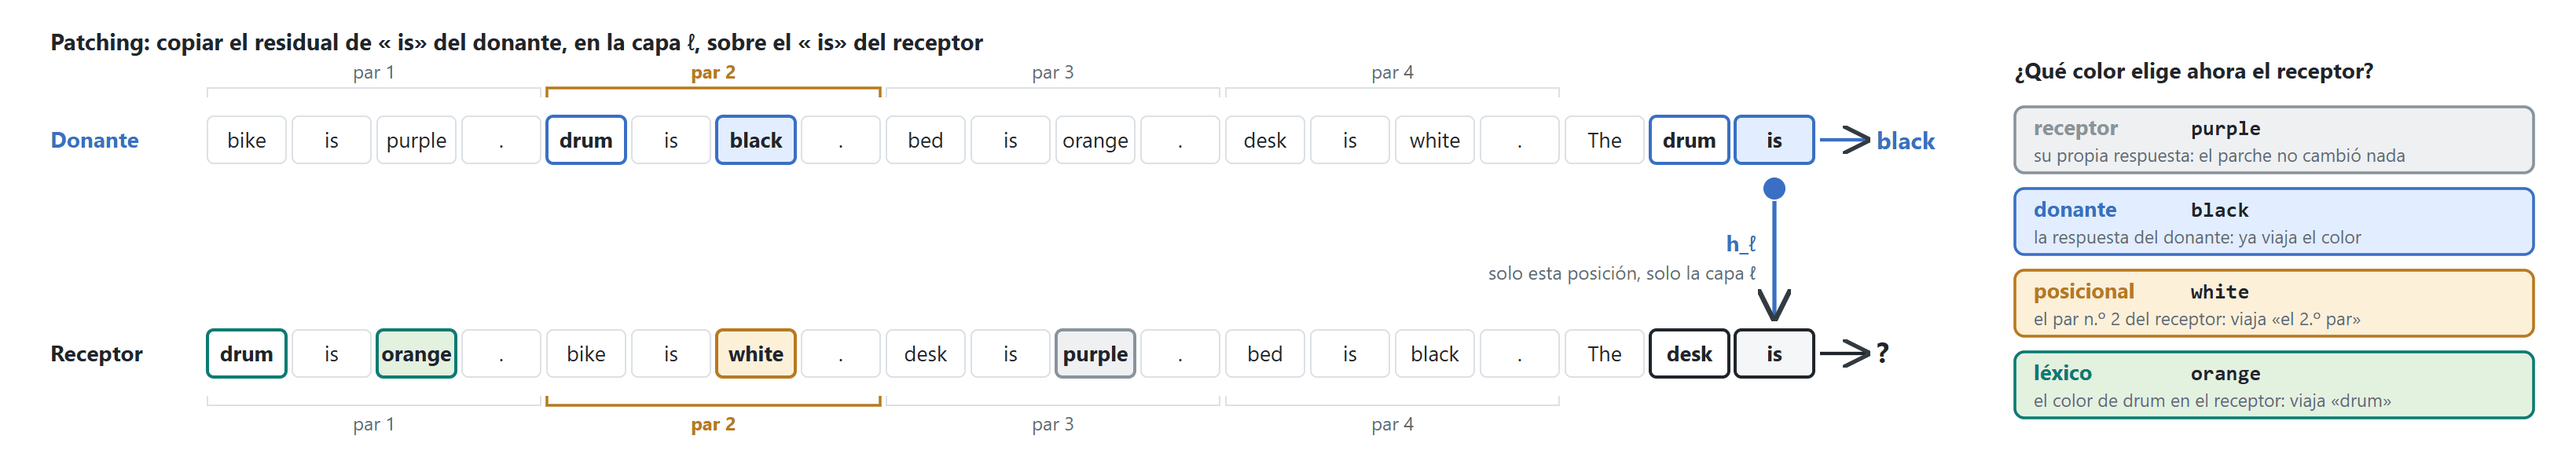

| desenlace | color predicho | qué significa |
|---|---|---|
| receptor | la respuesta del receptor | el parche no cambió nada |
| donante | la respuesta del donante | ya viaja el **color** recuperado |
| posicional | el color del receptor en el **mismo índice** que consultó el donante | viaja «el k-ésimo par» |
| léxico | el color que tiene en el receptor la **entidad** que consultó el donante | viaja «el objeto cup» |

Elegimos pares de prompts donde los cuatro desenlaces son colores distintos. Como en el paso 2, la predicción es el color
del contexto con mayor logit; «otro» = alguno de los otros cuatro colores del contexto.

> **Predice:** ¿en qué orden aparecen los desenlaces a medida que subimos de capa?

In [ ]:
def block_outputs(ids):
    """Salida de cada bloque en la última posición.
    (No usamos hidden_states: en Hugging Face el último ya viene normalizado.)"""
    outputs, hooks = {}, []
    for l, layer in enumerate(model.model.layers):
        def save(module, args, out, l=l):
            hidden = out[0] if isinstance(out, tuple) else out
            outputs[l] = hidden[0, -1].clone()
        hooks.append(layer.register_forward_hook(save))
    try:
        run_model(ids)
    finally:
        for hook in hooks:
            hook.remove()
    return outputs


def patch_hook(l, vector):
    """Reemplaza la salida del bloque l en la última posición por `vector`."""
    def replace(module, args, out):
        hidden = (out[0] if isinstance(out, tuple) else out).clone()
        hidden[0, -1] = vector
        return (hidden,) + tuple(out[1:]) if isinstance(out, tuple) else hidden
    return model.model.layers[l].register_forward_hook(replace)


def patch_pair(rng):
    """Receptor y donante con los mismos objetos y colores, en otro orden, y cuatro desenlaces distintos."""
    while True:
        receptor, q_r = sample_pairs(rng)
        objects = [o for o, _ in receptor]
        colors = [c for _, c in receptor]
        donor = list(zip(rng.sample(objects, NP), rng.sample(colors, NP)))
        q_d = rng.randrange(NP)
        outcomes = {'receptor': receptor[q_r][1],
                    'donante': donor[q_d][1],
                    'posicional': receptor[q_d][1],                 # mismo índice, en el receptor
                    'léxico': dict(receptor)[donor[q_d][0]]}        # misma entidad, en el receptor
        if len(set(outcomes.values())) == 4:
            return receptor, q_r, donor, q_d, outcomes


def patched_choices(receptor, q_r, donor, q_d, outcomes, layers):
    """Para cada capa: el color que elige el receptor parchado y a qué desenlace corresponde."""
    ids_r, _ = encode(receptor, q_r)
    ids_d, _ = encode(donor, q_d)
    assert ids_r.shape == ids_d.shape
    donor_states = block_outputs(ids_d)
    result = {}
    for l in layers:
        hook = patch_hook(l, donor_states[l])
        try:
            choice = choose_among_context(run_model(ids_r).logits[0, -1], receptor)
        finally:
            hook.remove()
        color = receptor[choice][1]
        kind = next((k for k, c in outcomes.items() if c == color), 'otro')
        result[l] = (color, kind)
    return result


KINDS = ['receptor', 'donante', 'posicional', 'léxico', 'otro']
KIND_COLORS = {'receptor': '#94a3b8', 'donante': BLUE, 'posicional': AMBER, 'léxico': GREEN, 'otro': PINK}

rng = random.Random(4)
N_PATCH = scaled(60)
fraction = {k: np.zeros(L) for k in KINDS}
t0 = time.time()
for _ in range(N_PATCH):
    for l, (color, kind) in patched_choices(*patch_pair(rng), layers=range(L)).items():
        fraction[kind][l] += 1 / N_PATCH
print(f'{N_PATCH} pares × {L} capas en {time.time() - t0:.0f}s')

plt.figure(figsize=(10, 3.5))
plt.stackplot(range(L), *[fraction[k] for k in KINDS], labels=KINDS, colors=[KIND_COLORS[k] for k in KINDS])
plt.xlabel('capa parchada (salida del bloque ℓ)')
plt.ylabel('fracción')
plt.xlim(0, L - 1)
plt.ylim(0, 1)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

> **Lee el gráfico:** ¿hay un tramo de capas donde domina «posicional» o «léxico»? ¿Desde qué capa el parche ya trae el
> **color** del donante? Compara con el logit lens y con la capa de las cabezas de recuperación. ¿Confirma o refuta tu
> hipótesis del paso 2?

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li>Capas 0–17: casi siempre «receptor» (el parche se sobrescribe).</li><li>Capas 18–21: <b>«léxico» ≈40%</b> contra «posicional» ≈15%. Lo que viaja es sobre todo la <b>entidad</b> («busca drum»), no el índice.</li><li>Desde la capa ≈20 crece «donante», que pasa de 75% desde la capa 24 y llega a ≈100% en la última: ahí ya viaja el <b>color</b>.</li><li>«Otro» (≈20% en las capas 18–25) son otros colores del contexto: errores honestos del modelo parchado.</li></ul></details>

### Dos ejemplos, capa por capa

Las fracciones esconden lo que pasa en cada prompt. Buscamos dos pares receptor–donante: uno cuyo parche pase por
**léxico** (receptor → léxico → donante) y otro que pase por **posicional**. Para algunas capas mostramos qué color elige el
receptor parchado. En el donante se marca su respuesta (azul); en el receptor, los colores de los otros tres desenlaces.

In [ ]:
from IPython.display import HTML, display

SHOW_LAYERS = sorted({0, 10, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, L - 1} & set(range(L)))

# Buscar un ejemplo para cada desenlace intermedio (léxico es frecuente; posicional, más raro)
rng = random.Random(7)
examples = {}
for _ in range(150):
    pair = patch_pair(rng)
    result = patched_choices(*pair, layers=SHOW_LAYERS)
    kinds_seen = {kind for _, kind in result.values()}
    if 'léxico' not in examples and {'receptor', 'léxico', 'donante'} <= kinds_seen:
        examples['léxico'] = (pair, result)
    if 'posicional' not in examples and {'receptor', 'posicional'} <= kinds_seen:
        examples['posicional'] = (pair, result)
    if len(examples) == 2:
        break


def colored(kind, text):
    return f'<b style="color:{KIND_COLORS[kind]}">{text}</b>'


def prompt_html(pairs, q, highlight):
    """El prompt con algunos colores resaltados (highlight: color → desenlace)."""
    def word(col):
        return colored(highlight[col], col) if col in highlight else col
    context = ' '.join(f'{obj} is {word(col)}.' for obj, col in pairs)
    return f'<code>{context} The <u>{pairs[q][0]}</u> is</code>'


def show_example(title, pair, result):
    receptor, q_r, donor, q_d, outcomes = pair
    in_receptor = {outcomes[k]: k for k in ('receptor', 'posicional', 'léxico')}   # en el receptor: tres desenlaces
    in_donor = {outcomes['donante']: 'donante'}                                    # en el donante: su respuesta
    rows = ''.join(f'<tr><td>{l}</td><td>{colored(kind, color)}</td><td style="color:{KIND_COLORS[kind]}">{kind}</td></tr>'
                   for l, (color, kind) in result.items())
    display(HTML(
        f'<h4>{title}</h4>'
        f'<p><b>Receptor</b> (consulta «{receptor[q_r][0]}», responde «{receptor[q_r][1]}»):<br>{prompt_html(receptor, q_r, in_receptor)}</p>'
        f'<p><b>Donante</b> (consulta «{donor[q_d][0]}», par n.º {q_d + 1}, responde «{donor[q_d][1]}»):<br>{prompt_html(donor, q_d, in_donor)}</p>'
        f'<p>Desenlaces posibles en el receptor: {colored("receptor", "receptor = " + outcomes["receptor"])} · '
        f'{colored("donante", "donante = " + outcomes["donante"])} (la respuesta del donante) · '
        f'{colored("posicional", "posicional = " + outcomes["posicional"])} (par n.º {q_d + 1} del receptor) · '
        f'{colored("léxico", "léxico = " + outcomes["léxico"])} (color de «{donor[q_d][0]}» en el receptor)</p>'
        f'<table><tr><th>capa parchada</th><th>color elegido</th><th>desenlace</th></tr>{rows}</table>'))


for kind, title in (('léxico', 'Ejemplo 1 · pasa por «léxico»'), ('posicional', 'Ejemplo 2 · pasa por «posicional»')):
    if kind in examples:
        show_example(title, *examples[kind])
    else:
        print(f'No apareció un ejemplo «{kind}» en 150 pares: prueba otra semilla en random.Random(7).')

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>Léxico</b> (receptor «… desk is purple … The desk is», donante «… drum is black … The drum is»): capas 0–18 → purple (receptor); <b>capa 19 → orange</b>, el color de drum <i>en el receptor</i>; capas 20–27 → black (donante).</li><li><b>Posicional</b> (receptor pregunta por «card»; donante pregunta por «drum», su par n.º 2): capas 15–21 → yellow, <b>el color del par n.º 2 del receptor</b>; desde la capa 22 → white (donante).</li><li>Entre las capas 19 y 20 se ve el paso de «qué buscar» a «lo encontrado». El puntero es léxico en algunos pares y posicional en otros, y el posicional dura más capas.</li></ul></details>

### 7c · ¿Son necesarias las cabezas que etiquetan cada color?

En la sección 6 encontramos cabezas que, desde el color, miran a **su** objeto (el «paso previo» de la tabla
inducción ↔ binding). Si son la mitad del circuito, apagarlas debería dañar la recuperación aunque las cabezas de
recuperación sigan intactas. Comparamos con el mismo número de cabezas al azar.

Ojo: la ablación apaga esas cabezas **en todas las posiciones**, no solo en los colores; por eso el control al azar es
importante.

> **Predice:** ¿qué daña más: apagar las 4 de etiquetado o las 4 de recuperación? ¿Y las dos juntas?

In [ ]:
rng_ctrl = random.Random(13)
ablation_tags = {
    'sin intervención': ablation['sin intervención'],
    '4 de etiquetado (color → objeto)': accuracy_with_ablation(tag_heads[:4]),
    '4 de recuperación (pregunta → color)': accuracy_with_ablation(top_heads[:4]),
    'las 8 juntas': accuracy_with_ablation(tag_heads[:4] + top_heads[:4]),
    '4 al azar': np.mean([accuracy_with_ablation(random_heads(rng_ctrl, 4)) for _ in range(3)]),
    '8 al azar': np.mean([accuracy_with_ablation(random_heads(rng_ctrl, 8)) for _ in range(3)]),
}

print('etiquetado:', ', '.join(f'L{l}.H{h}' for l, h in tag_heads[:4]))
print('recuperación:', ', '.join(f'L{l}.H{h}' for l, h in top_heads[:4]))
plt.figure(figsize=(8, 3.4))
plt.barh(list(ablation_tags)[::-1], list(ablation_tags.values())[::-1],
         color=['#334155', '#334155', PINK, PINK, AMBER, '#94a3b8'])
plt.axvline(1 / NP, ls='--', c='gray')
plt.xlim(0, 1)
plt.xlabel('exactitud')
plt.show()
print({k: round(float(v), 3) for k, v in ablation_tags.items()})

> **Lee el resultado:** si apagar las cabezas de etiquetado daña mucho más que apagar 4 al azar, tenemos evidencia causal
> de que el color «sabe» a qué objeto pertenece gracias a ellas, igual que la capa 1 del modelo de juguete. Si no daña,
> el etiquetado puede estar repartido en más cabezas (o hacerse por otra vía, como las MLP). ¿Qué concluyes?

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li>Sin intervención 93.3% · <b>4 de etiquetado 90.0%</b> · 4 de recuperación 82.5% · las 8 juntas 79.2% · 4 al azar 86.1% · 8 al azar 95.8%.</li><li>Apagar las 4 de etiquetado baja solo <b>3 puntos</b>, <b>menos que 4 cabezas al azar</b> (7 puntos, aunque el control es ruidoso: promedia 3 sorteos). Sumarlas a las de recuperación casi no agrega daño (82.5% → 79.2%).</li><li><b>Resultado negativo, y es útil:</b> que esas cabezas miren a su objeto (sección 6) no las hace necesarias. El etiquetado debe estar repartido en muchas cabezas o hacerse por las MLP. Atención ≠ causa.</li></ul></details>

## 8 · Paso 6 · Descomponer: PCA sin etiquetas

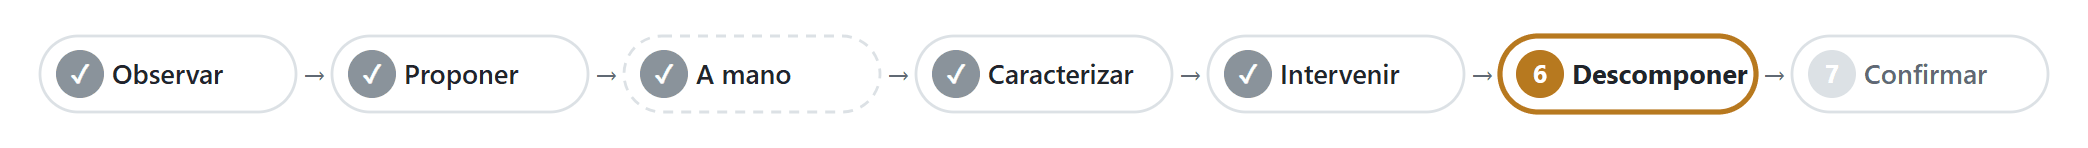

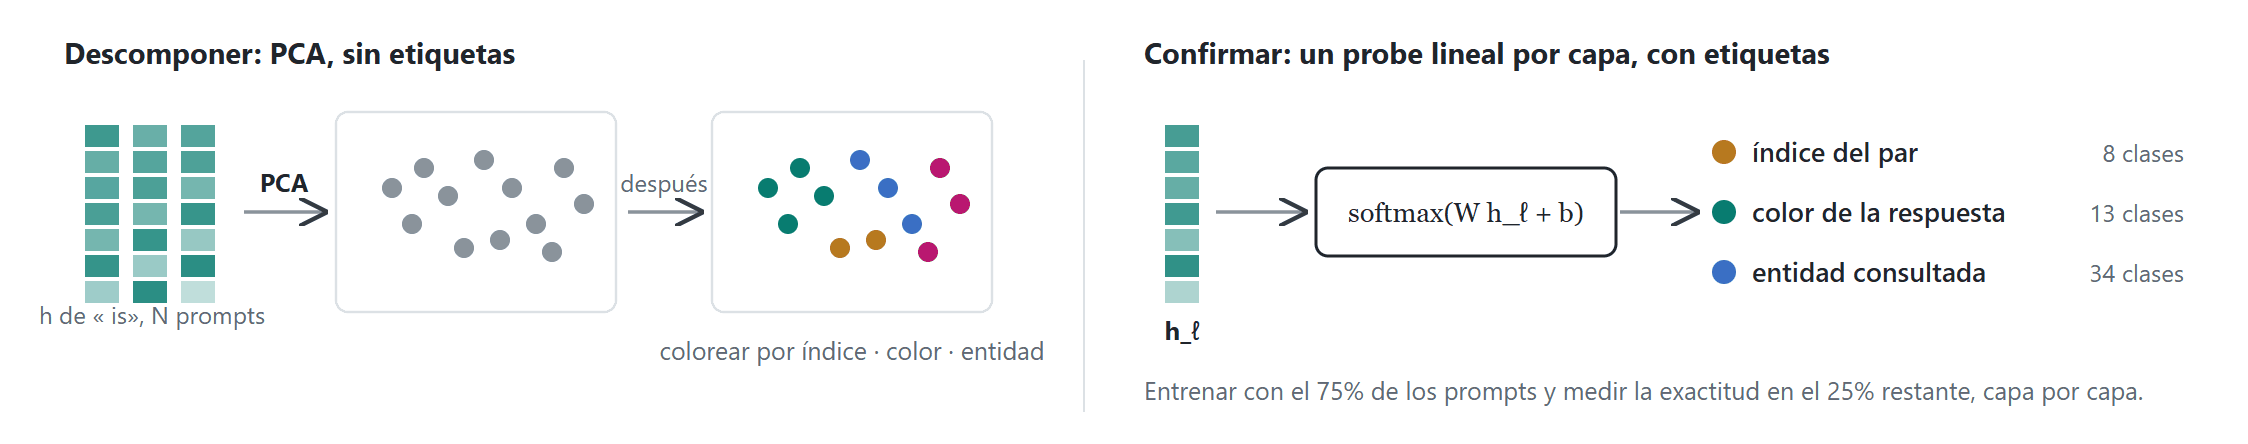

Proyectamos el residual de la última posición sobre sus dos primeras componentes principales, en tres capas. PCA no usa
etiquetas; **después** coloreamos los mismos puntos de tres formas: por el **índice** del par consultado, por el **color**
de la respuesta y por la **entidad** consultada.

> **Predice:** ¿qué variable organiza el espacio en cada capa?

In [ ]:
# Residual de la última posición en cada capa, para N_READ prompts, con tres etiquetas por prompt
rng = random.Random(5)
N_READ = scaled(400)
features = [[] for _ in range(L + 1)]
label_index, label_color, label_entity = [], [], []
for _ in range(N_READ):
    pairs, q = sample_pairs(rng)
    ids, _ = encode(pairs, q)
    hidden_states = run_model(ids, output_hidden_states=True).hidden_states
    for l in range(L + 1):
        features[l].append(hidden_states[l][0, -1].float().cpu().numpy())
    label_index.append(q)
    label_color.append(COLS.index(pairs[q][1]))
    label_entity.append(OBJS.index(pairs[q][0]))
features = [np.array(f) for f in features]
label_index, label_color, label_entity = map(np.array, (label_index, label_color, label_entity))


def pca_2d(X):
    """Proyección sobre las dos primeras componentes principales (sin etiquetas)."""
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T


# Fila 1: índice (0–7). Fila 2: el color de la respuesta, pintado con ese mismo color. Fila 3: la entidad.
NAMED = {'gray': 'gray', 'silver': '#a8a9ad', 'white': '#e5e7eb'}
answer_rgb = [NAMED.get(COLS[c], COLS[c]) for c in label_color]
layers_to_show = [L // 4, L // 2, 3 * L // 4]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for j, l in enumerate(layers_to_show):
    Z = pca_2d(features[l])
    sc = axes[0, j].scatter(Z[:, 0], Z[:, 1], c=label_index, cmap='viridis', s=12)
    axes[0, j].set_title(f'capa {l} · índice consultado')
    axes[1, j].scatter(Z[:, 0], Z[:, 1], c=answer_rgb, s=12, edgecolors='k', linewidths=.2)
    axes[1, j].set_title(f'capa {l} · color de la respuesta')
    axes[2, j].scatter(Z[:, 0], Z[:, 1], c=label_entity, cmap='nipy_spectral', s=12)
    axes[2, j].set_title(f'capa {l} · entidad consultada')
fig.colorbar(sc, ax=axes[0], label='índice del par')
plt.show()

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>Índice:</b> en las capas 14 y 21 los puntos forman un gradiente del par 0 al 7; en la capa 7, no.</li><li><b>Color de la respuesta:</b> no organiza las dos primeras componentes en ninguna capa, aunque el probe lo lea con 97% (sección 9). Legible no significa dominante en varianza.</li><li><b>Entidad:</b> en la capa 7 algunas entidades forman grupos aislados; desde la capa 14 manda el índice.</li></ul></details>

## 9 · Paso 7 · Confirmar: probes lineales

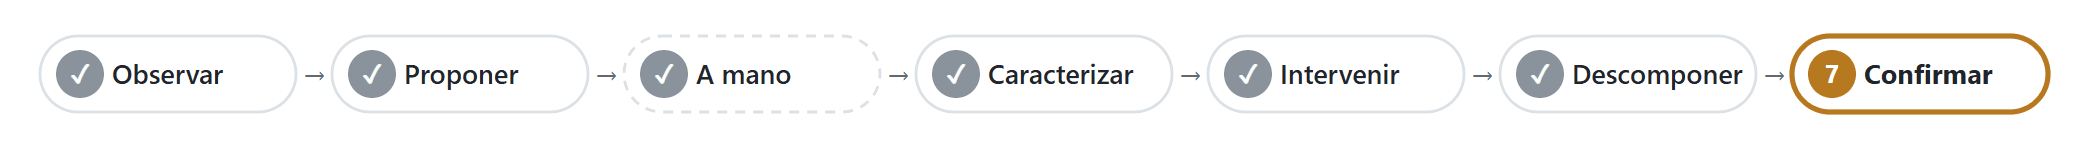

Un clasificador lineal por capa, entrenado con el 75% de los ejemplos y evaluado en el resto, intenta leer desde la
última posición (a) el **índice** del par consultado, (b) el **color** de la respuesta y (c) la **entidad** consultada.
El azar es distinto para cada una: 1/8 para el índice, 1/13 para el color y 1/34 para la entidad.

> **Predice:** ¿qué variable se vuelve legible primero?

In [ ]:
N_TRAIN = int(N_READ * 0.75)


def probe_accuracy(labels):
    """Exactitud de test de un probe lineal (regresión logística) en cada capa."""
    accuracy = []
    for l in range(L + 1):
        X = features[l]
        X = (X - X[:N_TRAIN].mean(0)) / (X[:N_TRAIN].std(0) + 1e-6)     # estandarizar con las estadísticas de entrenamiento
        clf = LogisticRegression(max_iter=2000, C=0.05).fit(X[:N_TRAIN], labels[:N_TRAIN])
        accuracy.append(clf.score(X[N_TRAIN:], labels[N_TRAIN:]))
    return np.array(accuracy)


probes = {'índice del par consultado': (probe_accuracy(label_index), AMBER, 1 / NP),
          'color de la respuesta': (probe_accuracy(label_color), GREEN, 1 / len(COLS)),
          'entidad consultada': (probe_accuracy(label_entity), BLUE, 1 / len(OBJS))}

plt.figure(figsize=(9, 3.5))
for name, (accuracy, color, chance) in probes.items():
    plt.plot(accuracy, label=name, c=color)
    plt.axhline(chance, ls=':', c=color, lw=1)
plt.xlabel('capa')
plt.ylabel('exactitud de test')
plt.ylim(0, 1.02)
plt.title('Probes lineales (punteado: azar de cada variable)')
plt.legend(loc='lower right')
plt.show()

<details><summary><b>Lo que encontramos en nuestra corrida</b> (ábrelo después de responder)</summary><ul><li><b>Entidad: 100% desde la capa 1.</b> Es una trampa: la última posición lee el objeto de la pregunta, que está dos tokens antes (L1.H4 lo mira con 0.90). Que una variable sea <i>legible</i> no significa que el modelo haya resuelto algo con ella.</li><li><b>Índice:</b> sube desde la capa ≈4 y queda en 60–77% entre las capas 8 y 21. Saber qué par se consulta exige buscar en la lista.</li><li><b>Color:</b> cerca del azar hasta la capa 19 y <b>salta a 83% en la capa 20</b> (≈97% al final), justo después de las cabezas L19–20. Coincide con el patching: desde la capa 20 viaja el color.</li></ul></details>

## 10 · Cierre

Completa la tabla con lo que encontraste:

| paso | herramienta | lo que viste | tipo de evidencia |
|---|---|---|---|
| 1 · Observar | logit lens, atención | … | observación |
| 2 · Proponer | hipótesis por etapas | … | — |
| 3 · Demostrar a mano | (no aplica) | … | plausibilidad |
| 4 · Caracterizar | atención al objeto vs. al color por capa | … | consistencia |
| 5 · Intervenir | ablación, patching | … | causal |
| 6 · Descomponer | PCA | … | correlacional |
| 7 · Confirmar | probes | … | correlacional |

**Para seguir:**
- Cambia `MODEL_ID` a `Qwen/Qwen2.5-0.5B-Instruct` o `Qwen/Qwen2.5-3B-Instruct` y corre todo de nuevo. ¿Se mueven las capas
  clave en proporción al número de capas?
- Repite el patching parchando la posición del **objeto consultado** en la pregunta (penúltimo token) en vez de la última.
- ¿Qué pasa si dos objetos comparten color? Diseña el prompt y predice el resultado antes de correrlo.

**Referencias:** Feng & Steinhardt (2023), *How do language models bind entities in context?*; Dai et al. (2024),
*Representational analysis of binding in language models*; Wu et al. (2024), *Retrieval head mechanistically explains
long-context factuality*; nostalgebraist (2020), *interpreting GPT: the logit lens*; Heimersheim & Nanda (2024), *How to use
and interpret activation patching*.